# Классификация
## 1. Постановка задачи классификации

Дана выборка $X = \{(x_i, y_i)\}_{i=1}^n$, где $x_i \in \mathbb{R}^d$ — признаки, $y_i \in \{1,\dots,K\}$ — метка класса.

**Задача:** построить $a(x)$, предсказывающий класс для нового объекта.

**Бинарный случай:** $y_i \in \{0,1\}$. Класс 1 обычно называют «положительным».

**Ключевое отличие от регрессии:** ответ дискретный.

**Схема решения:**
1. EDA (типы, пропуски, баланс классов)
2. Препроцессинг (кодирование, масштабирование)
3. Train/test split (стратифицированный)
4. Baseline (Dummy)
5. Обучение моделей, метрики
6. Анализ ошибок и важности признаков

**Правило без утечек:** все параметры преобразований (медианы, scaler, encoder) вычисляются только на train.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

sns.set_style('whitegrid')
np.random.seed(42)

X, y = make_classification(n_samples=1000, n_features=10, n_informative=6,
                           n_redundant=2, n_classes=2, weights=[0.6, 0.4],
                           random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)
print('Train:', X_train.shape, 'Test:', X_test.shape)

from sklearn.datasets import make_moons

X2, y2 = make_moons(n_samples=300, noise=0.25, random_state=42)
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.3, random_state=42, stratify=y2)
sc2 = StandardScaler().fit(X2_train)
X2_train_sc = sc2.transform(X2_train)
X2_test_sc = sc2.transform(X2_test)

def plot_boundary(model, X, y, title, ax=None, annotate=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 300),
                         np.linspace(X[:,1].min()-1, X[:,1].max()+1, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')
    ax.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm', edgecolor='k', s=40)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('Признак 1'); ax.set_ylabel('Признак 2')
    if annotate:
        for text, xy, xytext in annotate:
            ax.annotate(text, xy=xy, xytext=xytext, fontsize=10,
                        arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
                        bbox=dict(boxstyle='round,pad=0.3', fc='yellow', alpha=0.8))
    return ax


Train: (750, 10) Test: (250, 10)


### Почему логистическая регрессия работает

Логистическая регрессия — линейная модель для оценки вероятности класса. Линейная комбинация признаков переводится в интервал от 0 до 1 с помощью сигмоиды. Обучение обычно сводится к минимизации логарифмической потери (log loss).

Регуляризация ограничивает величину коэффициентов: L2 сглаживает веса, а L1 может занулять некоторые из них. При интерпретации коэффициентов важно помнить, что их масштабы зависят от единиц измерения признаков. Порог 0,5 не универсален: его можно менять в зависимости от цены ложноположительных и ложноотрицательных решений.


## 2. Логистическая регрессия

**Модель:**
$$p(y=1|x) = \sigma(w^T x + b), \quad \sigma(z) = \frac{1}{1+e^{-z}}$$

**Решение:** $\hat{y} = \mathbb{1}[p \ge 0.5]$.

**Функция потерь** (кросс-энтропия / логистическая):
$$L(w) = -\frac{1}{n}\sum_{i=1}^n [y_i \log p_i + (1-y_i)\log(1-p_i)]$$

**Свойства:**
- Линейная разделяющая поверхность
- Даёт вероятности (калиброванные)
- Требует масштабирования для устойчивой сходимости градиентного спуска
- Параметр $C$ — обратная сила L2-регуляризации

**Sklearn:** `LogisticRegression(max_iter=5000)`.

Accuracy: 0.7880
Precision: 0.7238
Recall: 0.7600
F1: 0.7415


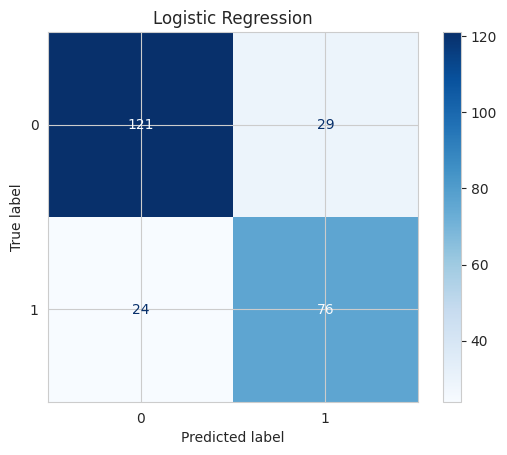

In [ ]:
lr = LogisticRegression(max_iter=5000).fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)

print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1: {f1_score(y_test, y_pred_lr):.4f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_lr),
                       display_labels=['0','1']).plot(cmap='Blues')
plt.title('Logistic Regression')
plt.show()


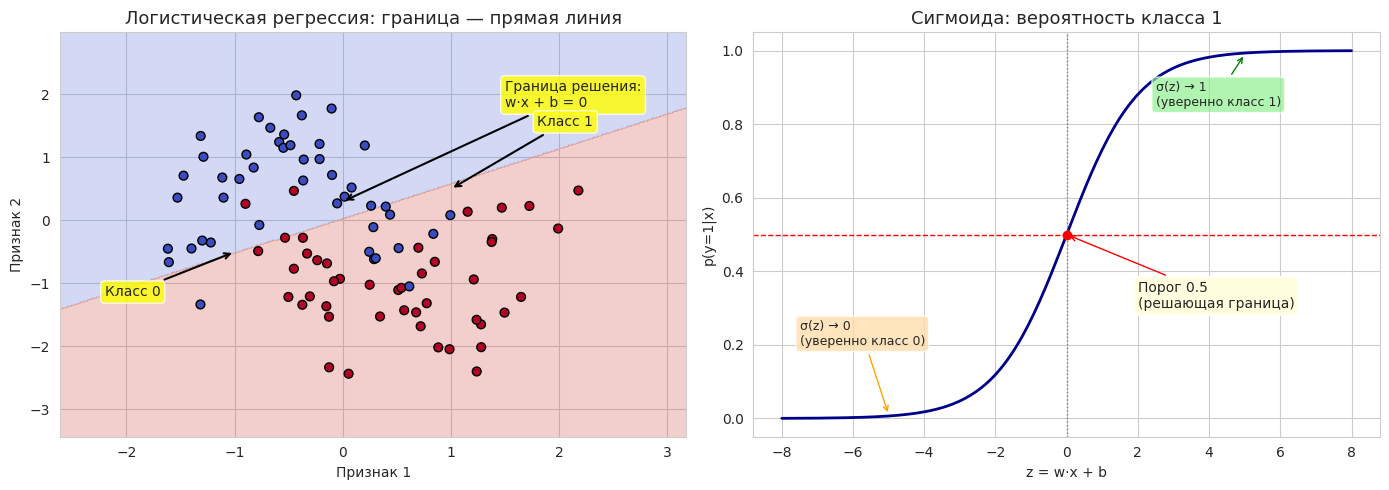

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lr2 = LogisticRegression().fit(X2_train_sc, y2_train)
plot_boundary(lr2, X2_test_sc, y2_test,
              'Логистическая регрессия: граница — прямая линия',
              ax=axes[0],
              annotate=[('Граница решения:\nw·x + b = 0',
                         (0, 0.3), (1.5, 1.8)),
                        ('Класс 0', (-1, -0.5), (-2.2, -1.2)),
                        ('Класс 1', (1, 0.5), (1.8, 1.5))])

z = np.linspace(-8, 8, 200)
sig = 1 / (1 + np.exp(-z))
axes[1].plot(z, sig, lw=2, color='darkblue')
axes[1].axhline(0.5, color='red', ls='--', lw=1)
axes[1].axvline(0, color='gray', ls=':', lw=1)
axes[1].scatter([0], [0.5], color='red', zorder=5)
axes[1].annotate('Порог 0.5\n(решающая граница)', xy=(0, 0.5), xytext=(2, 0.3),
                 fontsize=10, arrowprops=dict(arrowstyle='->', color='red'),
                 bbox=dict(boxstyle='round', fc='lightyellow'))
axes[1].annotate('σ(z) → 1\n(уверенно класс 1)', xy=(5, 0.99), xytext=(2.5, 0.85),
                 fontsize=9, arrowprops=dict(arrowstyle='->', color='green'),
                 bbox=dict(boxstyle='round', fc='lightgreen', alpha=0.7))
axes[1].annotate('σ(z) → 0\n(уверенно класс 0)', xy=(-5, 0.01), xytext=(-7.5, 0.2),
                 fontsize=9, arrowprops=dict(arrowstyle='->', color='orange'),
                 bbox=dict(boxstyle='round', fc='navajowhite', alpha=0.8))
axes[1].set_title('Сигмоида: вероятность класса 1', fontsize=13)
axes[1].set_xlabel('z = w·x + b'); axes[1].set_ylabel('p(y=1|x)')
axes[1].grid(True)

plt.tight_layout(); plt.show()


### Выбор метрики

Accuracy показывает долю верных ответов, но при редком положительном классе может быть обманчивой. Precision отвечает на вопрос «какая доля предсказанных положительных объектов действительно положительна», а recall — «какую долю всех положительных объектов мы нашли». F1 объединяет precision и recall гармоническим средним.

Для сравнения моделей полезно смотреть также на матрицу ошибок, PR-кривую и ROC-AUC. Порог классификации выбирают на валидационных данных, а тестовую выборку оставляют для итоговой оценки.


## 3. Метрики качества классификации

**Confusion matrix** (1 — положительный класс):

|            | Предсказано 0 | Предсказано 1 |
|------------|---------------|---------------|
| **Истинно 0** | TN         | FP            |
| **Истинно 1** | FN         | TP            |

- **TP** — верно нашли положительный
- **TN** — верно отклонили отрицательный
- **FP** (ложная тревога) — сказали 1, а истина 0
- **FN** (пропуск) — сказали 0, а истина 1

**Метрики:**
$$\text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN}$$
$$\text{Precision} = \frac{TP}{TP+FP}$$
$$\text{Recall} = \frac{TP}{TP+FN}$$
$$F_1 = \frac{2 \cdot P \cdot R}{P + R}$$

**Проблема Accuracy:** при дисбалансе (90% класса 0) модель «всегда 0» даёт accuracy 90%, но Recall = 0. Поэтому в бинарной классификации с дисбалансом смотрят на F1.

**Что важнее, FP или FN?** Зависит от задачи:
- Медицина (рак): критичен FN (пропустить болезнь)
- Спам: критичен FP (удалить важное письмо)

In [ ]:

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print("=== Dummy (most_frequent) ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dummy):.4f}")
print(f"F1: {f1_score(y_test, y_pred_dummy):.4f}  ← accuracy высокая, но F1=0")
print("\n=== Logistic Regression ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"F1: {f1_score(y_test, y_pred_lr):.4f}")


=== Dummy (most_frequent) ===
Accuracy: 0.6000
F1: 0.0000  ← accuracy высокая, но F1=0

=== Logistic Regression ===
Accuracy: 0.7880
F1: 0.7415


### Теория: сложность дерева

Дерево решений последовательно делит пространство признаков на области. При каждом разбиении выбирается признак и порог, которые сильнее уменьшают неоднородность классов. Глубокие деревья способны почти запомнить обучающую выборку, поэтому глубину, минимальный размер листа и другие ограничения подбирают на валидации.


## 4. Дерево решений

**Идея:** рекурсивно разбиваем пространство по порогам, выбирая разбиение, максимально уменьшающее неоднородность.

**Критерии:**
- Gini: $1 - \sum_k p_k^2$
- Entropy: $-\sum_k p_k \log p_k$

**Свойства:**
- Не требует масштабирования
- Легко переобучается (контроль: `max_depth`, `min_samples_leaf`)
- Нестабильно: малые изменения данных → другое дерево
- `feature_importances_` смещена к признакам с большим числом уникальных значений

DT train acc: 0.8587
DT test  acc: 0.7760
Разрыв train-test = признак переобучения


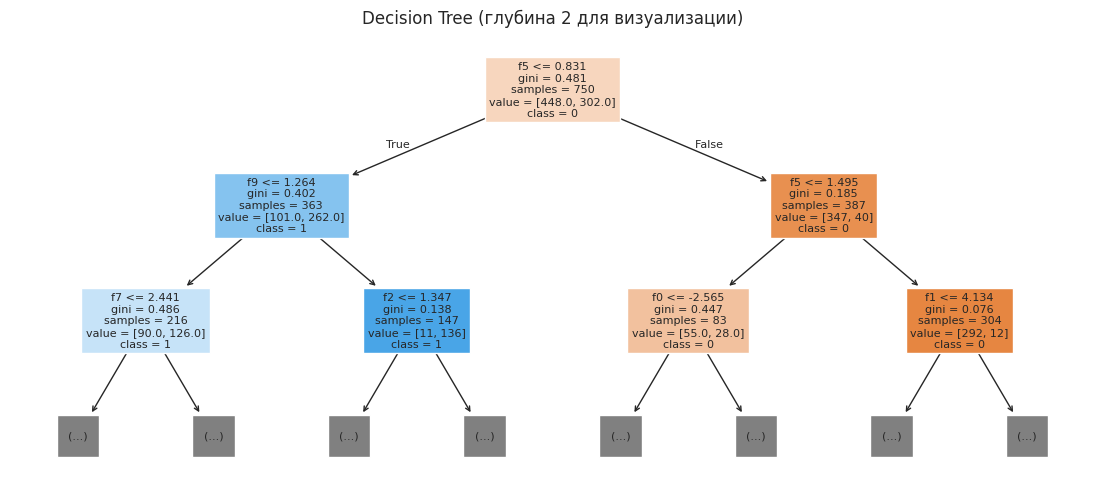

In [ ]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print(f"DT train acc: {accuracy_score(y_train, dt.predict(X_train)):.4f}")
print(f"DT test  acc: {accuracy_score(y_test, y_pred_dt):.4f}")
print("Разрыв train-test = признак переобучения")

plt.figure(figsize=(14, 6))
plot_tree(dt, filled=True, feature_names=[f'f{i}' for i in range(X.shape[1])],
          class_names=['0','1'], max_depth=2)
plt.title('Decision Tree (глубина 2 для визуализации)')
plt.show()


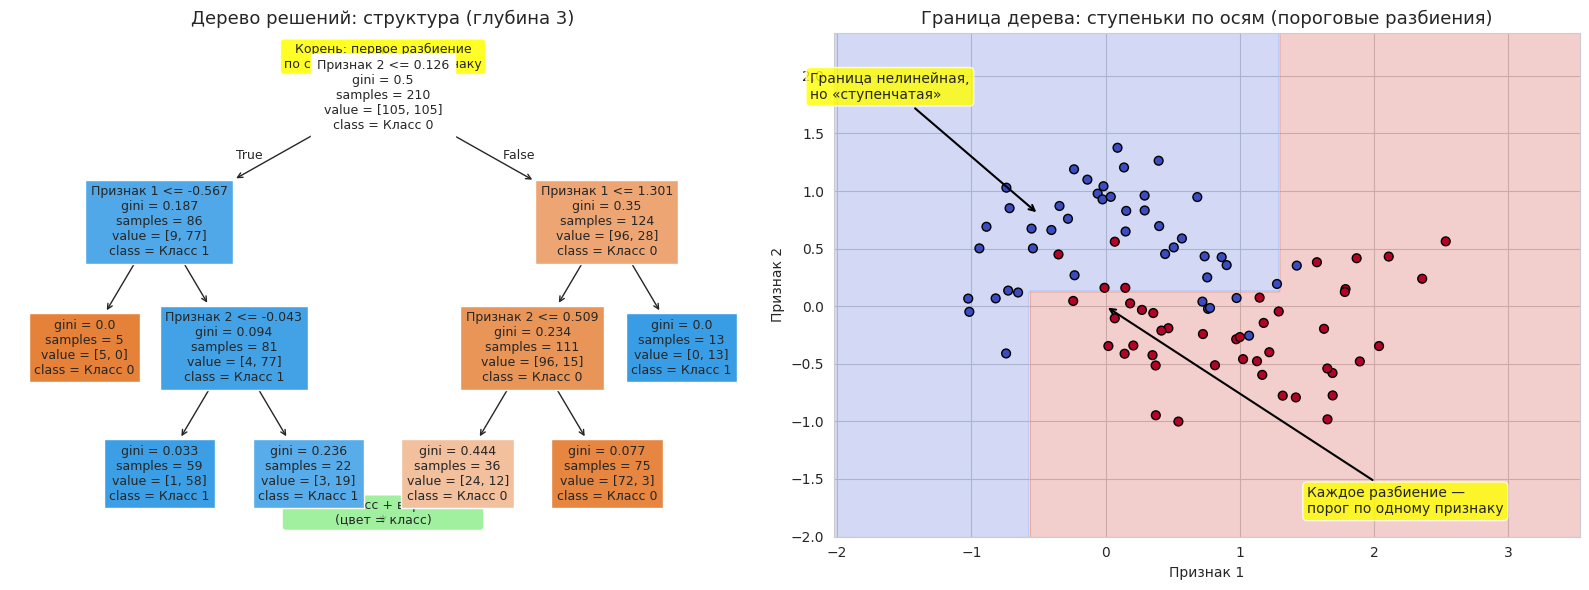

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dt2 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X2_train, y2_train)
plot_tree(dt2, filled=True, feature_names=['Признак 1', 'Признак 2'],
          class_names=['Класс 0', 'Класс 1'], ax=axes[0], fontsize=9)
axes[0].set_title('Дерево решений: структура (глубина 3)', fontsize=13)

axes[0].annotate('Корень: первое разбиение\nпо самому важному признаку',
                 xy=(0.5, 0.98), xycoords='axes fraction',
                 ha='center', va='top', fontsize=9,
                 bbox=dict(boxstyle='round,pad=0.3', fc='yellow', alpha=0.85),
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.2))
axes[0].annotate('Листья: класс + вероятность\n(цвет = класс)',
                 xy=(0.5, 0.02), xycoords='axes fraction',
                 ha='center', va='bottom', fontsize=9,
                 bbox=dict(boxstyle='round,pad=0.3', fc='lightgreen', alpha=0.85),
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.2))

plot_boundary(dt2, X2_test, y2_test,
              'Граница дерева: ступеньки по осям (пороговые разбиения)',
              ax=axes[1],
              annotate=[('Каждое разбиение —\nпорог по одному признаку',
                         (0, 0), (1.5, -1.8)),
                        ('Граница нелинейная,\nно «ступенчатая»',
                         (-0.5, 0.8), (-2.2, 1.8))])

plt.tight_layout()
plt.show()


### Бэггинг и случайный лес

Случайный лес уменьшает разброс предсказаний за счёт усреднения многих деревьев. Каждое дерево обучается на bootstrap-выборке, а при поиске разбиения рассматривает случайное подмножество признаков. Разнообразие деревьев особенно важно: одинаковые ошибки отдельных моделей усреднением не устраняются.


## 5. Random Forest

**Идея:** $B$ деревьев на bootstrap-подвыборках. В каждом узле — случайное подмножество признаков ($\sqrt{d}$). Предсказание — голосование.

**Почему работает:** усреднение некоррелированных деревьев снижает variance без роста bias.

**Свойства:**
- Устойчивее одиночного дерева
- Не требует масштабирования
- `feature_importances_` — среднее по деревьям, но также смещена
- Параметры: `n_estimators`, `max_features`, `max_depth`

In [ ]:
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(f"RF F1: {f1_score(y_test, y_pred_rf):.4f}")


RF F1: 0.8529


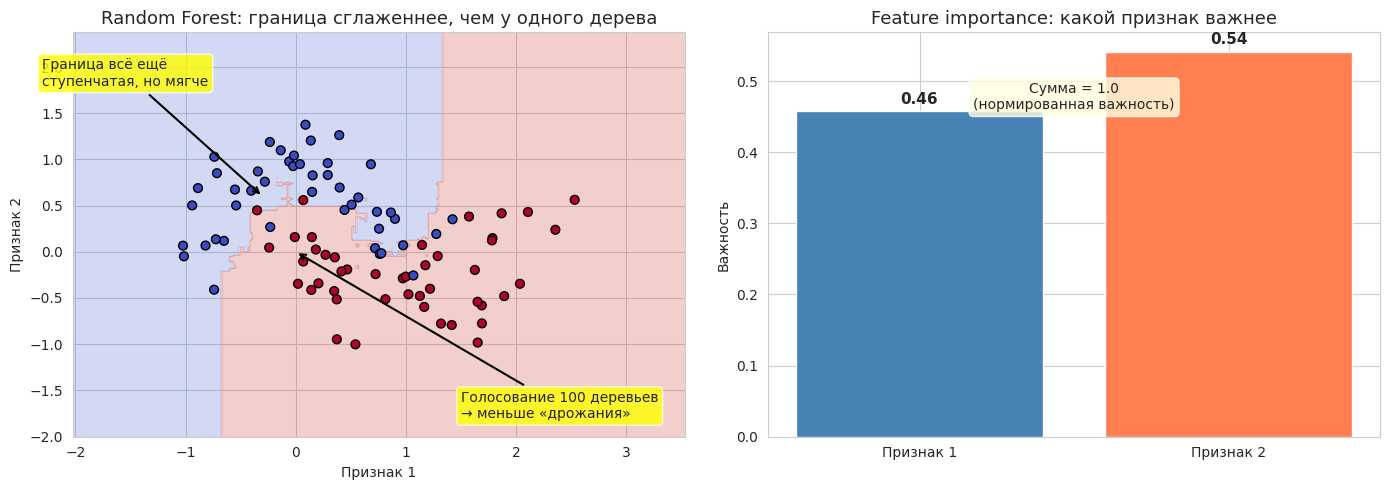

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf2 = RandomForestClassifier(n_estimators=100, random_state=42).fit(X2_train, y2_train)
plot_boundary(rf2, X2_test, y2_test,
              'Random Forest: граница сглаженнее, чем у одного дерева',
              ax=axes[0],
              annotate=[('Голосование 100 деревьев\n→ меньше «дрожания»',
                         (0, 0), (1.5, -1.8)),
                        ('Граница всё ещё\nступенчатая, но мягче',
                         (-0.3, 0.6), (-2.3, 1.8))])

imp = rf2.feature_importances_
bars = axes[1].bar(['Признак 1', 'Признак 2'], imp, color=['steelblue', 'coral'])
axes[1].set_title('Feature importance: какой признак важнее', fontsize=13)
axes[1].set_ylabel('Важность')
for bar, v in zip(bars, imp):
    axes[1].text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.2f}',
                 ha='center', fontsize=11, fontweight='bold')
axes[1].annotate('Сумма = 1.0\n(нормированная важность)',
                 xy=(0.5, max(imp)*0.85), xycoords='data', ha='center',
                 fontsize=10, bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.8))

plt.tight_layout(); plt.show()


### Теория: градиентный бустинг

В отличие от случайного леса, бустинг строит модели последовательно. На каждом шаге новая слабая модель приближает направление уменьшения выбранной функции потерь. Для классификации это не обязательно обычные остатки $y-\hat y$: точнее говорить об антиградиенте потерь.

Темп обучения (`learning_rate`), число деревьев и их сложность совместно определяют качество и риск переобучения.


## 6. Gradient Boosting

**Идея:** последовательное построение. Каждое новое дерево учится на **остатках** (градиентах потерь) предыдущего ансамбля.

$$F_m(x) = F_{m-1}(x) + \nu \cdot h_m(x)$$

где $\nu$ — learning rate.

**Отличие от RF:**
- RF: параллельный бэггинг, снижает variance
- GB: последовательный, снижает bias (и variance)
- GB сильнее на табличных данных, но чувствителен к гиперпараметрам

**Свойства:**
- Не требует масштабирования
- Переобучается при большом `n_estimators` без early stopping
- `feature_importances_` есть

In [ ]:
gb = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
print(f"GB F1: {f1_score(y_test, y_pred_gb):.4f}")


GB F1: 0.8155


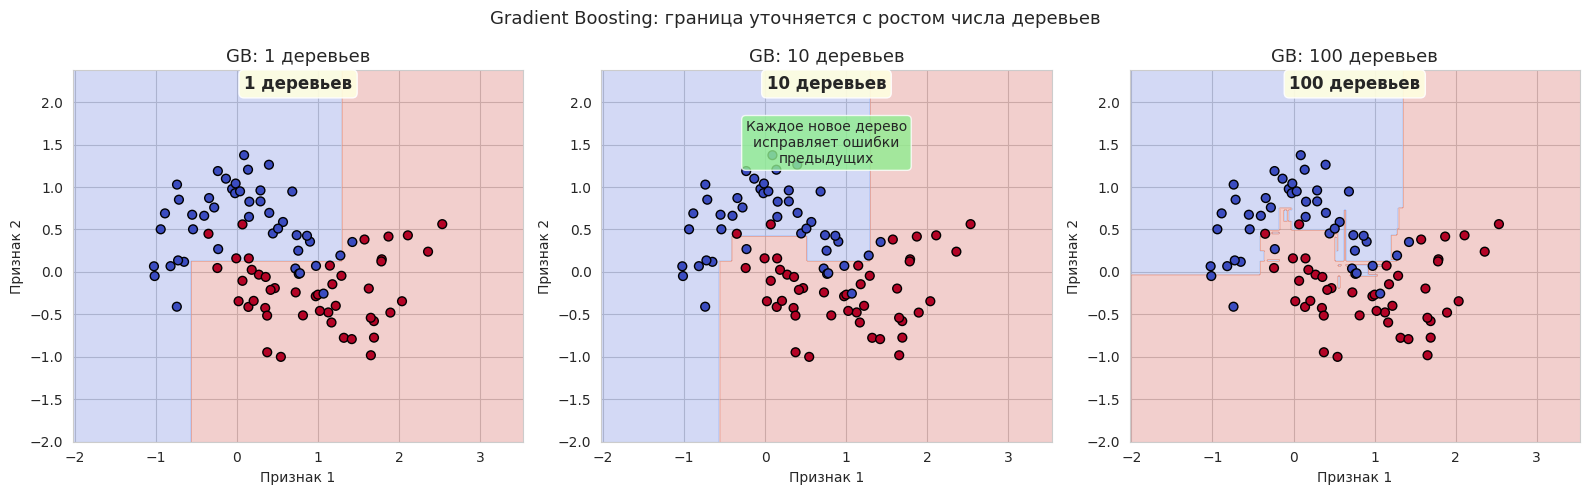

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
n_trees_list = [1, 10, 100]

for ax, n in zip(axes, n_trees_list):
    gb2 = GradientBoostingClassifier(n_estimators=n, random_state=42).fit(X2_train, y2_train)
    plot_boundary(gb2, X2_test, y2_test, f'GB: {n} деревьев', ax=ax)
    ax.annotate(f'{n} деревьев',
                xy=(0.5, 0.95), xycoords='axes fraction', ha='center',
                fontsize=12, fontweight='bold',
                bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.9))

axes[1].annotate('Каждое новое дерево\nисправляет ошибки\nпредыдущих',
                 xy=(0.5, 0.75), xycoords='axes fraction', ha='center',
                 fontsize=10, bbox=dict(boxstyle='round', fc='lightgreen', alpha=0.8))
plt.suptitle('Gradient Boosting: граница уточняется с ростом числа деревьев', fontsize=13)
plt.tight_layout(); plt.show()


### Максимальный зазор

Линейный SVM ищет разделяющую гиперплоскость с максимально широким зазором между классами. Параметр `C` управляет штрафом за нарушения зазора: большое значение сильнее наказывает ошибки на обучении. Ядро RBF позволяет строить нелинейные границы без явного перехода к признакам высокой размерности. Масштабирование особенно важно для методов, основанных на расстояниях и скалярных произведениях.


## 7. Support Vector Machine

**Идея:** максимизируем зазор (margin) между классами. Опорные векторы — ближайшие к границе объекты.

**Soft margin:** параметр $C$ — компромисс margin vs ошибки.

**Kernel trick:** замена скалярного произведения на ядро $K(x_i,x_j)$. RBF: $\exp(-\gamma\|x-z\|^2)$.

**Ключевое:** **обязательно масштабирование**. Зазор и расстояния чувствительны к масштабу: признак с большим разбросом подавит остальные. Без StandardScaler SVM даст плохой результат.

**Параметры:** `C`, `kernel` ('linear', 'rbf'), `gamma`.

In [ ]:
svm_sc = SVC(kernel='rbf', random_state=42).fit(X_train_sc, y_train)
y_pred_svm = svm_sc.predict(X_test_sc)
print(f"SVM со scaling, F1: {f1_score(y_test, y_pred_svm):.4f}")

svm_raw = SVC(kernel='rbf', random_state=42).fit(X_train, y_train)
print(f"SVM без scaling, F1: {f1_score(y_test, svm_raw.predict(X_test)):.4f}")


SVM со scaling, F1: 0.8824
SVM без scaling, F1: 0.8856


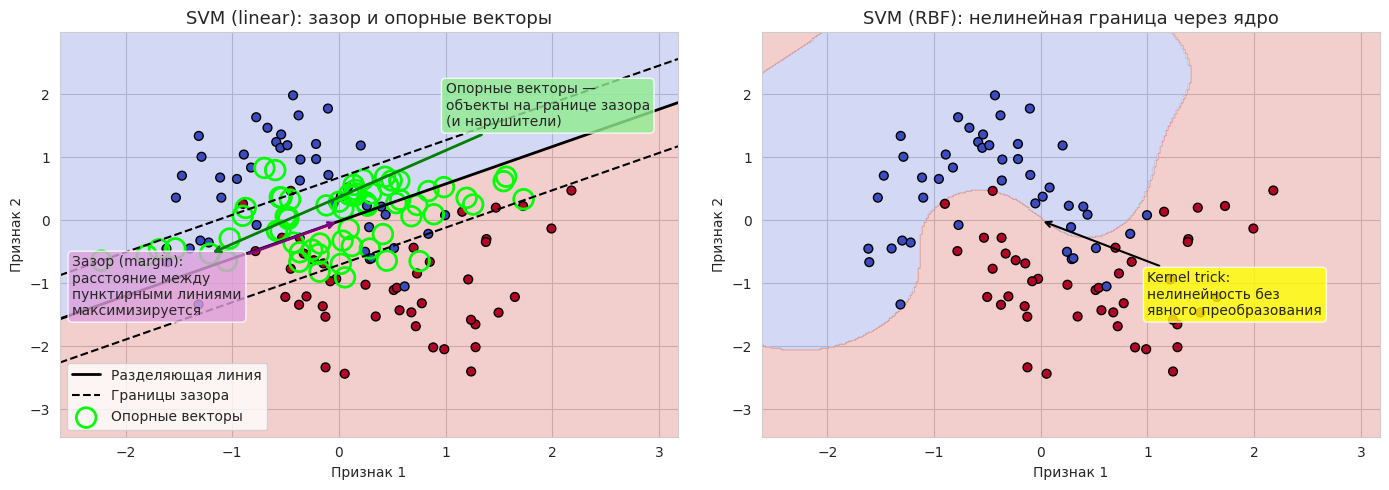

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

svm_lin = SVC(kernel='linear', C=10.0).fit(X2_train_sc, y2_train)
plot_boundary(svm_lin, X2_test_sc, y2_test,
              'SVM (linear): зазор и опорные векторы', ax=axes[0])

w = svm_lin.coef_[0]
b = svm_lin.intercept_[0]

x_min, x_max = axes[0].get_xlim()
xx = np.linspace(x_min, x_max, 100)

yy = -(w[0] * xx + b) / w[1]
axes[0].plot(xx, yy, 'k-', lw=2, label='Разделяющая линия')

yy_down = -(w[0] * xx + b - 1) / w[1]
yy_up = -(w[0] * xx + b + 1) / w[1]
axes[0].plot(xx, yy_down, 'k--', lw=1.5, label='Границы зазора')
axes[0].plot(xx, yy_up, 'k--', lw=1.5)

sv = svm_lin.support_vectors_
axes[0].scatter(sv[:, 0], sv[:, 1], s=200, facecolors='none',
                edgecolors='lime', linewidths=2, label='Опорные векторы')

mid_x = 0
mid_y = -(w[0] * mid_x + b) / w[1]
axes[0].annotate('Зазор (margin):\nрасстояние между\nпунктирными линиями\nмаксимизируется',
                 xy=(mid_x, mid_y), xytext=(-2.5, -1.5),
                 arrowprops=dict(arrowstyle='->', color='purple', lw=2),
                 fontsize=10, bbox=dict(boxstyle='round', fc='plum', alpha=0.8))

axes[0].annotate('Опорные векторы —\nобъекты на границе зазора\n(и нарушители)',
                 xy=tuple(sv[0]), xytext=(1.0, 1.5),
                 arrowprops=dict(arrowstyle='->', color='green', lw=2),
                 fontsize=10, bbox=dict(boxstyle='round', fc='lightgreen', alpha=0.8))

axes[0].legend(loc='lower left')

svm_rbf = SVC(kernel='rbf', gamma=1.0).fit(X2_train_sc, y2_train)
plot_boundary(svm_rbf, X2_test_sc, y2_test,
              'SVM (RBF): нелинейная граница через ядро', ax=axes[1],
              annotate=[('Kernel trick:\nнелинейность без\nявного преобразования',
                         (0, 0), (1.0, -1.5))])

plt.tight_layout()
plt.show()


Тут зеленые кружочки немного (сильно) неровно

### Метод ближайших соседей

KNN не строит явную параметрическую модель: при прогнозе он ищет близкие обучающие объекты и определяет класс голосованием. Малое $k$ делает границу чувствительной к шуму, большое — более гладкой, но может скрывать локальную структуру. Выбор метрики расстояния и масштаба признаков непосредственно влияет на результат.


## 8. K-Nearest Neighbors

**Идея:** для нового объекта — $k$ ближайших соседей в train, голосование большинства.

**Метрика:** евклидово расстояние.

**Ключевое:** **критично масштабирование**. Расстояние доминируется признаком с большим разбросом. Без scaler KNN фактически игнорирует малые по масштабу признаки.

**Параметры:**
- $k$: малое → переобучение, большое → сглаживание
- `weights`: 'uniform' или 'distance'

**Свойства:**
- Ленивое обучение (вся работа при предсказании)
- Нет `feature_importances_`
- Чувствителен к размерности

In [ ]:
knn_sc = KNeighborsClassifier(n_neighbors=5).fit(X_train_sc, y_train)
y_pred_knn = knn_sc.predict(X_test_sc)
print(f"KNN со scaling, F1: {f1_score(y_test, y_pred_knn):.4f}")

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print(f"KNN без scaling, F1: {f1_score(y_test, knn_raw.predict(X_test)):.4f}")


KNN со scaling, F1: 0.8955
KNN без scaling, F1: 0.8911


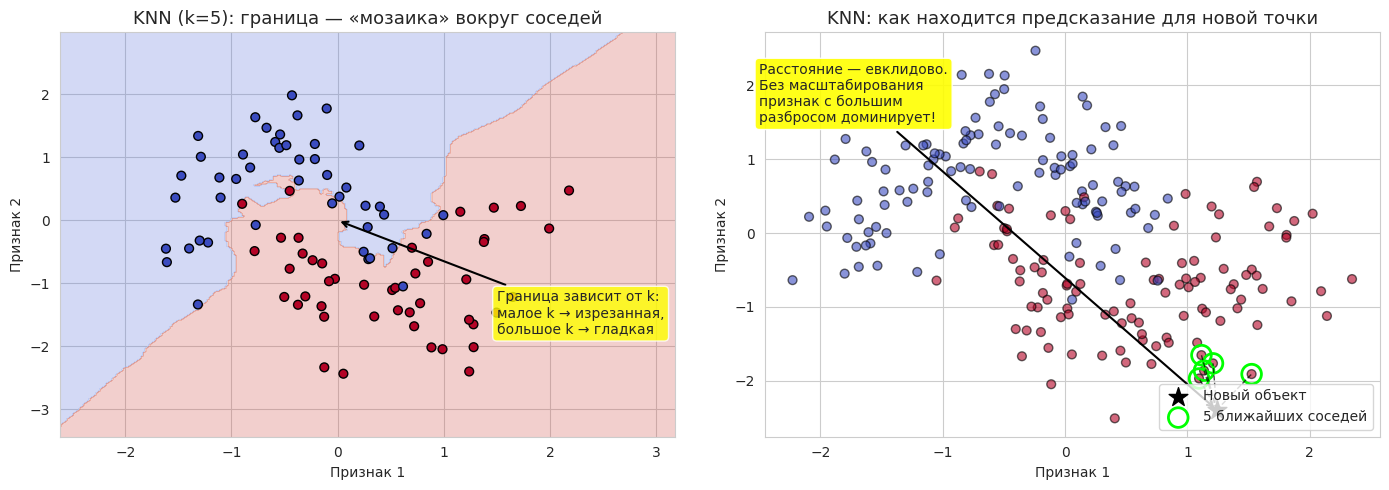

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

knn2 = KNeighborsClassifier(n_neighbors=5).fit(X2_train_sc, y2_train)
plot_boundary(knn2, X2_test_sc, y2_test,
              'KNN (k=5): граница — «мозаика» вокруг соседей', ax=axes[0],
              annotate=[('Граница зависит от k:\nмалое k → изрезанная,\nбольшое k → гладкая',
                         (0, 0), (1.5, -1.8))])

query = X2_test_sc[0]
dists = np.linalg.norm(X2_train_sc - query, axis=1)
nn_idx = np.argsort(dists)[:5]

axes[1].scatter(X2_train_sc[:, 0], X2_train_sc[:, 1], c=y2_train,
                cmap='coolwarm', edgecolor='k', s=40, alpha=0.6)

axes[1].scatter(*query, c='black', s=200, marker='*', label='Новый объект', zorder=5)

for i in nn_idx:
    axes[1].plot([query[0], X2_train_sc[i, 0]], [query[1], X2_train_sc[i, 1]],
                 'k--', lw=1, alpha=0.7)
axes[1].scatter(X2_train_sc[nn_idx, 0], X2_train_sc[nn_idx, 1],
                s=200, facecolors='none', edgecolors='lime', linewidths=2,
                label='5 ближайших соседей')

axes[1].legend(loc='lower right')
axes[1].set_title('KNN: как находится предсказание для новой точки', fontsize=13)
axes[1].set_xlabel('Признак 1')
axes[1].set_ylabel('Признак 2')

axes[1].annotate('Расстояние — евклидово.\nБез масштабирования\nпризнак с большим\nразбросом доминирует!',
                 xy=query, xytext=(-2.5, 1.5),
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
                 fontsize=10, bbox=dict(boxstyle='round', fc='yellow', alpha=0.9))

plt.tight_layout()
plt.show()


### Теория: интерпретация результатов

Важность признака показывает, насколько он полезен для конкретной модели и способа измерения, но сама по себе не доказывает причинное влияние. Встроенная важность деревьев может быть смещена; permutation importance оценивает изменение качества после перемешивания значений признака. При сильной корреляции признаков и этот подход требует осторожности.


## 9. Важность признаков и причинность

**Два подхода:**

1. **`feature_importances_`** (DT/RF/GB): на основе уменьшения неоднородности. Быстро, но **смещена** — завышает важность признаков с большим числом уникальных значений и коррелированных признаков.

2. **Permutation importance**: перемешиваем значения признака на test и смотрим падение метрики. Медленнее, но честнее и работает для любой модели (включая SVM/KNN).

**Критически важно:** важность признака **не означает причинность**. Признак может быть важным, потому что коррелирует с целевой переменной через скрытый фактор. Пример: «пол» может быть важен, но причина выживания — не пол сам по себе, а политика спасения. Feature importance — это про предсказание, не про причинно-следственные связи.

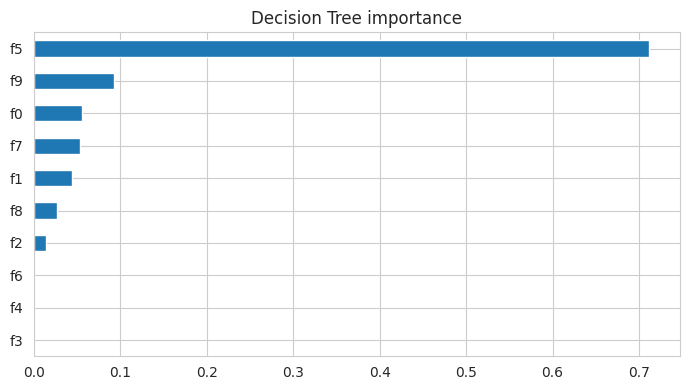

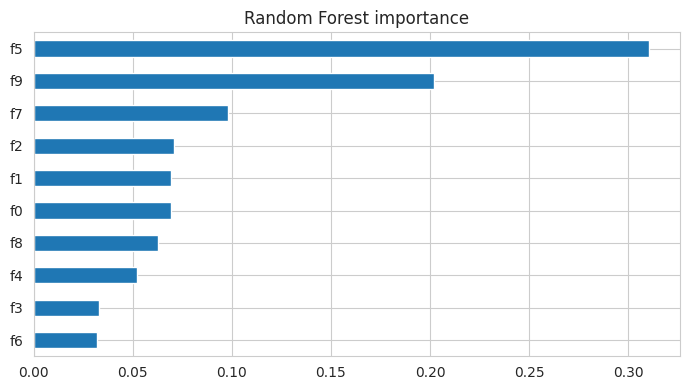

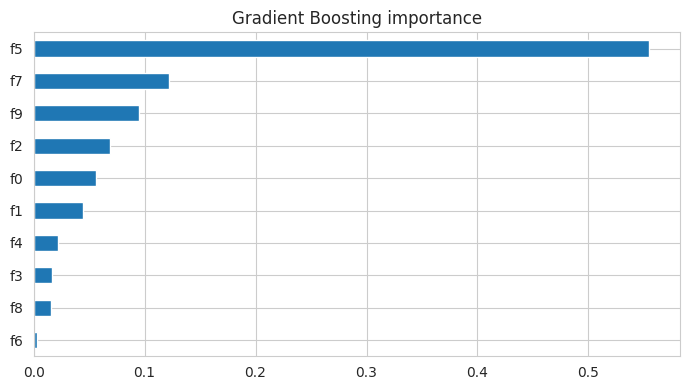

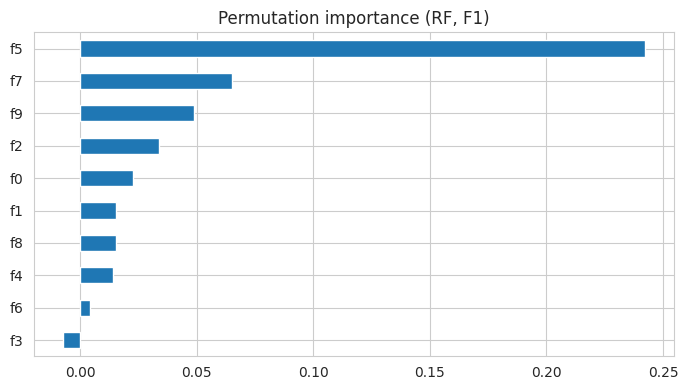

In [ ]:
def plot_importance(model, title):
    imp = pd.Series(model.feature_importances_,
                    index=[f'f{i}' for i in range(X.shape[1])]).sort_values()
    imp.plot(kind='barh', figsize=(7, 4))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_importance(dt, 'Decision Tree importance')
plot_importance(rf, 'Random Forest importance')
plot_importance(gb, 'Gradient Boosting importance')

perm = permutation_importance(rf, X_test, y_test, n_repeats=20,
                              random_state=42, scoring='f1')
pd.Series(perm.importances_mean,
          index=[f'f{i}' for i in range(X.shape[1])]).sort_values().plot(
    kind='barh', figsize=(7, 4))
plt.title('Permutation importance (RF, F1)')
plt.tight_layout()
plt.show()


## Шпаргалка: что важно запомнить

| Модель | Масштабирование | Переобучение | Feature importance |
|--------|-----------------|--------------|---------------------|
| LogReg | Да | Слабое (регуляризация) | Коэффициенты |
| DT | Нет | Сильное | Да (смещена) |
| RF | Нет | Слабое | Да (смещена) |
| GB | Нет | Среднее | Да (смещена) |
| SVM | **Обязательно** | Зависит от C | Нет (используй permutation) |
| KNN | **Критично** | Зависит от k | Нет (используй permutation) |

**Главные тезисы:**
1. Accuracy обманчива при дисбалансе → F1.
2. Scaling обязателен для SVM и KNN.
3. Feature importance ≠ причинность.
4. Baseline (Dummy) нужен, чтобы понять, «насколько модель лучше тупого угадывания».


## Дополнительная теория и источники

**Обобщающая способность.** Хорошая модель должна работать не только на обучающей выборке, но и на новых данных. Большая разница между качеством на train и test часто указывает на переобучение. Для подбора гиперпараметров применяют кросс-валидацию, а тест используют после завершения выбора модели.

**Компромисс смещения и разброса (bias–variance).** Слишком простая модель не улавливает закономерности (высокое смещение), а слишком сложная может реагировать на случайный шум (высокий разброс). Регуляризация, ограничения сложности и ансамбли помогают управлять этим компромиссом.

**Практическое правило.** Начинать стоит с простого baseline, затем сравнивать несколько моделей при одинаковом разбиении данных и одной выбранной метрике. Любое масштабирование и подбор параметров должны выполняться без утечки информации из теста.

### Для дальнейшего изучения

- **MIT OpenCourseWare — 6.036 Introduction to Machine Learning.** Линейные классификаторы, обобщение, регуляризация, оценка моделей: https://ocw.mit.edu/courses/6-036-introduction-to-machine-learning-fall-2020/
- **MIT OpenCourseWare — 6.867 Machine Learning.** Теоретические основы машинного обучения: https://ocw.mit.edu/courses/6-867-machine-learning-fall-2006/
- **Курсы А. Соколова по машинному обучению.** Для точной привязки тезисов к лекциям и указания страниц требуется ссылка на конкретный курс или конспект Соколова; изложенная выше теория не представлена как дословная цитата из него.

**Вопросы для самопроверки:** почему accuracy недостаточно при дисбалансе классов? Чем бустинг отличается от бэггинга? Почему масштабирование важно для SVM и KNN? Почему важность признака не равна причинности?
